<a href="https://colab.research.google.com/github/pranjalgahlot123/Privacy-Preserving-Federated-Learning-Framework/blob/main/Privacy_Preserving_Federated_Learning_Framework_with_Secure_Aggregation_and_Differential_Privacy_for_Distributed_AI_Systems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading Breast Cancer Dataset...
Training Centralized Model (Baseline)...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Starting Federated Learning...
Round 1: FL Accuracy = 56.14%
Round 2: FL Accuracy = 26.32%
Round 3: FL Accuracy = 25.44%
Round 4: FL Accuracy = 49.12%
Round 5: FL Accuracy = 73.68%
Round 6: FL Accuracy = 84.21%
Round 7: FL Accuracy = 50.00%
Round 8: FL Accuracy = 75.44%
Round 9: FL Accuracy = 69.30%
Round 10: FL Accuracy = 73.68%
Round 11: FL Accuracy = 81.58%
Round 12: FL Accuracy = 65.79%
Round 13: FL Accuracy = 57.89%
Round 14: FL Accuracy = 64.91%
Round 15: FL Accuracy = 64.04%
Graphs saved! Check your Colab file explorer.


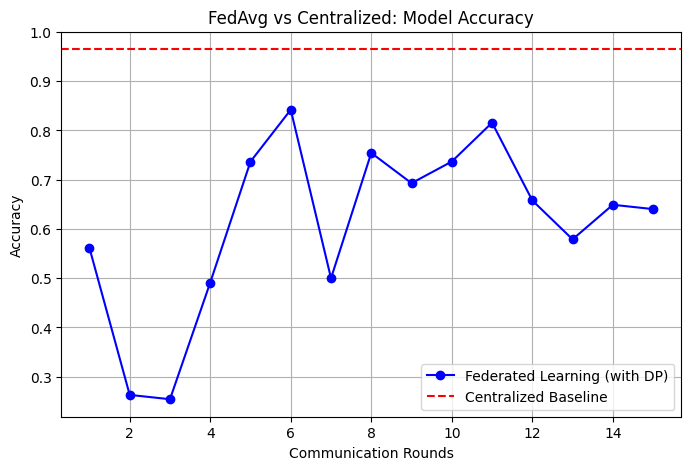

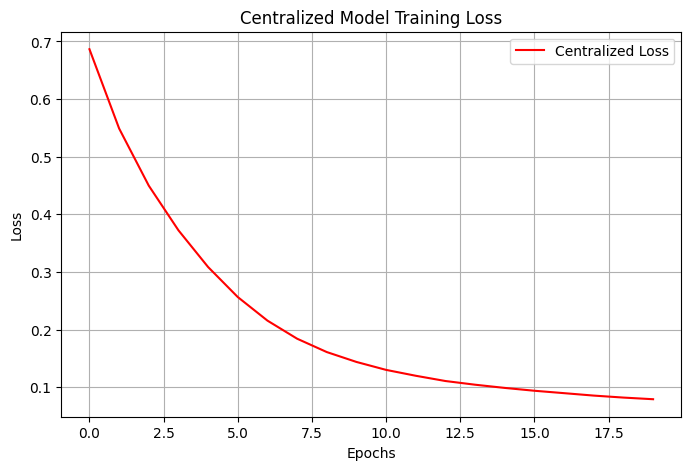

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import copy

# ==========================================
# 1. LOAD REAL DATASET (Healthcare)
# ==========================================
print("Loading Breast Cancer Dataset...")
data = load_breast_cancer()
X, y = data.data, data.target

# Normalize data
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split into Global Test set (20%) and Training set (80%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Split Training data into 3 "Hospitals" (Non-IID simulation)
# Hospital 1 gets 33%, Hospital 2 gets 33%, Hospital 3 gets 34%
split = len(X_train) // 3
X_clients = [X_train[:split], X_train[split:2*split], X_train[2*split:]]
y_clients = [y_train[:split], y_train[split:2*split], y_train[2*split:]]

# ==========================================
# 2. DEFINE NEURAL NETWORK & DP NOISE
# ==========================================
def create_model():
    model = Sequential([
        Dense(16, activation='relu', input_shape=(X.shape[1],)),
        Dense(8, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

def add_dp_noise(weights, epsilon=1.0):
    """Adds Laplacian noise for Differential Privacy"""
    noisy_weights = []
    for w in weights:
        noise = np.random.laplace(0, 1/epsilon, size=w.shape)
        noisy_weights.append(w + noise)
    return noisy_weights

# ==========================================
# 3. BASELINE: CENTRALIZED ML
# ==========================================
print("Training Centralized Model (Baseline)...")
central_model = create_model()
history_central = central_model.fit(X_train, y_train, epochs=20, batch_size=32, verbose=0, validation_data=(X_test, y_test))
central_acc = central_model.evaluate(X_test, y_test, verbose=0)[1]

# ==========================================
# 4. FEDERATED LEARNING LOOP
# ==========================================
print("Starting Federated Learning...")
global_model = create_model()
rounds = 15
fl_accuracies = []

for round_num in range(1, rounds + 1):
    client_weights = []

    for i in range(3):
        # Client trains local model
        local_model = create_model()
        local_model.set_weights(global_model.get_weights())
        local_model.fit(X_clients[i], y_clients[i], epochs=3, batch_size=32, verbose=0)

        # Apply Differential Privacy
        weights = local_model.get_weights()
        noisy_weights = add_dp_noise(weights, epsilon=2.0) # Try epsilon 0.5 for more privacy, 5.0 for less
        client_weights.append(noisy_weights)

    # Server Aggregates (FedAvg)
    new_weights = []
    for layer_idx in range(len(client_weights[0])):
        layer_avg = np.mean([client_weights[client][layer_idx] for client in range(3)], axis=0)
        new_weights.append(layer_avg)

    global_model.set_weights(new_weights)

    # Evaluate Federated Model
    loss, acc = global_model.evaluate(X_test, y_test, verbose=0)
    fl_accuracies.append(acc)
    print(f"Round {round_num}: FL Accuracy = {acc*100:.2f}%")

# ==========================================
# 5. GENERATE PUBLICATION GRAPHS
# ==========================================
# Graph 1: Centralized vs Federated Accuracy
plt.figure(figsize=(8, 5))
plt.plot(range(1, rounds + 1), fl_accuracies, marker='o', label='Federated Learning (with DP)', color='blue')
plt.axhline(y=central_acc, color='red', linestyle='--', label='Centralized Baseline')
plt.title('FedAvg vs Centralized: Model Accuracy')
plt.xlabel('Communication Rounds')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.savefig('graph1_comparison.png')

# Graph 2: Training Loss
plt.figure(figsize=(8, 5))
plt.plot(history_central.history['loss'], label='Centralized Loss', color='red')
plt.title('Centralized Model Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.savefig('graph2_loss.png')

print("Graphs saved! Check your Colab file explorer.")